# Propensity Score Matching: Subreddit Comparison

This notebook applies propensity score matching to compare outcomes between two subreddits while controlling for confounding variables.

**Research Question**: Does posting in Subreddit A vs Subreddit B lead to different outcomes (e.g., sentiment, engagement) after controlling for post characteristics?


## Setup


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
import time

%matplotlib inline

# Set random seed for reproducibility
np.random.seed(42)

# Quick test: verify NumPy is fast now
_test_start = time.time()
_ = np.random.randn(100000)
_test_time = time.time() - _test_start
if _test_time < 1.0:
    print(f"✓ NumPy initialized fast ({_test_time:.3f}s) - fix worked!")
else:
    print(f"⚠ NumPy still slow ({_test_time:.3f}s) - restart kernel and run from top")


✓ NumPy initialized fast (0.003s) - fix worked!


## Load Data and Select Subreddits



In [2]:
import pickle
import pandas as pd
import numpy as np
import time

print("Starting to load pickle file...")
start_time = time.time()
# with open("../../data/reddit_df_final_superclusters.pkl", "rb") as f:
#     df_pd = pickle.load(f)
# print(f"✓ Pickle loaded in {time.time() - start_time:.2f}s. Shape: {df_pd.shape}")

import os
os.chdir('../..')
print(f"Current directory: {os.getcwd()}")

from src.utils.data_utils import load_final_df

df_pd = load_final_df()

print("\nScanning columns for list types...")
scan_start = time.time()
list_cols = []
for i, c in enumerate(df_pd.columns):
    col_start = time.time()
    s = df_pd[c]
    if s.apply(lambda x: isinstance(x, list)).any():
        list_cols.append(c)
        print(f"  Column {i+1}/{len(df_pd.columns)}: '{c}' is a list column ({time.time() - col_start:.2f}s)")
    elif (i + 1) % 10 == 0:
        print(f"  Checked {i+1}/{len(df_pd.columns)} columns...")
        
print(f"✓ Column scan complete in {time.time() - scan_start:.2f}s")
print("List columns detected:", list_cols)

print("\nCleaning list columns...")
cleanup_start = time.time()
for c in list_cols:
    print(f"  Cleaning column '{c}'...")
    col_start = time.time()
    df_pd[c] = df_pd[c].apply(lambda x: x if isinstance(x, list) else None)
    print(f"  ✓ '{c}' cleaned in {time.time() - col_start:.2f}s")

print(f"✓ Cleanup complete in {time.time() - cleanup_start:.2f}s")
print(f"\n=== TOTAL TIME: {time.time() - start_time:.2f}s ===")
print("DataFrame is ready (pandas only).")

Starting to load pickle file...
Current directory: /home/naimer/github/ADA/ada-2025-project-standard-deviants-ada

Scanning columns for list types...
  Checked 10/197 columns...
  Checked 20/197 columns...
  Checked 30/197 columns...
  Checked 40/197 columns...
  Checked 50/197 columns...
  Checked 60/197 columns...
  Checked 70/197 columns...
  Checked 80/197 columns...
  Checked 90/197 columns...
  Checked 100/197 columns...
  Column 105/197: 'user_reports' is a list column (0.11s)
  Column 110/197: 'link_flair_richtext' is a list column (0.11s)
  Checked 120/197 columns...
  Checked 130/197 columns...
  Column 139/197: 'content_categories' is a list column (0.11s)
  Checked 140/197 columns...
  Checked 150/197 columns...
  Column 158/197: 'all_awardings' is a list column (0.11s)
  Column 159/197: 'awarders' is a list column (0.11s)
  Checked 160/197 columns...
  Checked 170/197 columns...
  Checked 180/197 columns...
  Column 190/197: 'mod_reports' is a list column (0.11s)
✓ Column 

In [3]:
print(df_pd.columns.tolist())
print([type(x) for x in df_pd.columns])


['SOURCE_SUBREDDIT', 'TARGET_SUBREDDIT', 'POST_ID', 'TIMESTAMP', 'LINK_SENTIMENT', 'source_type', 'Num_characters', 'Num_characters_no_space', 'Frac_alpha', 'Frac_digits', 'Frac_uppercase', 'Frac_whitespace', 'Frac_special', 'Num_words', 'Num_unique_words', 'Num_long_words', 'Avg_word_length', 'Num_unique_stopwords', 'Frac_stopwords', 'Num_sentences', 'Num_long_sentences', 'Avg_chars_per_sentence', 'Avg_words_per_sentence', 'Automated_readability_index', 'Sentiment_pos_vader', 'Sentiment_neg_vader', 'Sentiment_compound_vader', 'LIWC_Funct', 'LIWC_Pronoun', 'LIWC_Ppron', 'LIWC_I', 'LIWC_We', 'LIWC_You', 'LIWC_SheHe', 'LIWC_They', 'LIWC_Ipron', 'LIWC_Article', 'LIWC_Verbs', 'LIWC_AuxVb', 'LIWC_Past', 'LIWC_Present', 'LIWC_Future', 'LIWC_Adverbs', 'LIWC_Prep', 'LIWC_Conj', 'LIWC_Negate', 'LIWC_Quant', 'LIWC_Numbers', 'LIWC_Swear', 'LIWC_Social', 'LIWC_Family', 'LIWC_Friends', 'LIWC_Humans', 'LIWC_Affect', 'LIWC_Posemo', 'LIWC_Negemo', 'LIWC_Anx', 'LIWC_Anger', 'LIWC_Sad', 'LIWC_CogMech', 

In [4]:
# make the analysis dataframe
df_analysis = df_pd.copy()

df_analysis['Sentiment_compound_vader'] = pd.to_numeric(df_analysis['Sentiment_compound_vader'], errors='coerce')
df_analysis['virality_rss'] = pd.to_numeric(df_analysis['virality_rss'], errors='coerce')

df_analysis = df_analysis[
    df_analysis['Sentiment_compound_vader'].notna() &
    df_analysis['virality_rss'].notna() &
    (df_analysis['Sentiment_compound_vader'] != 0)
].copy()

# Define treatment: 1 = positive VADER, 0 = negative VADER
df_analysis['treat'] = (df_analysis['Sentiment_compound_vader'] > 0).astype(int)

print("Treatment is defined as positive VADER sentiment.")

print("Analysis dataset shape:", df_analysis.shape)
print("Number of positive (treat=1) posts:", (df_analysis['treat'] == 1).sum())
print("Number of negative (treat=0) posts:", (df_analysis['treat'] == 0).sum())

Treatment is defined as positive VADER sentiment.
Analysis dataset shape: (456817, 198)
Number of positive (treat=1) posts: 280703
Number of negative (treat=0) posts: 176114


## Step 1: Naive Analysis (Before Matching)

Compare outcomes without any adjustments (similar to LaLonde example).


In [5]:
# Separate grovirality_rss (like in the LaLonde example)
treated = df_analysis[df_analysis['treat'] == 1]
control = df_analysis[df_analysis['treat'] == 0]

# Outcome variable (already set above, but repeated here for clarity)
outcome_var = 'virality_rss'

print("Treated group (positive sentiment):"); print(treated[outcome_var].describe())
print("\nControl group (negative sentiment):"); print(control[outcome_var].describe())


Treated group (positive sentiment):
count    280703.000000
mean          0.199571
std           0.935019
min           0.000000
25%           0.008004
50%           0.045968
75%           0.168574
max         202.646563
Name: virality_rss, dtype: float64

Control group (negative sentiment):
count    176114.000000
mean          0.255969
std           1.187084
min           0.000000
25%           0.009540
50%           0.061975
75%           0.230802
max         173.179989
Name: virality_rss, dtype: float64


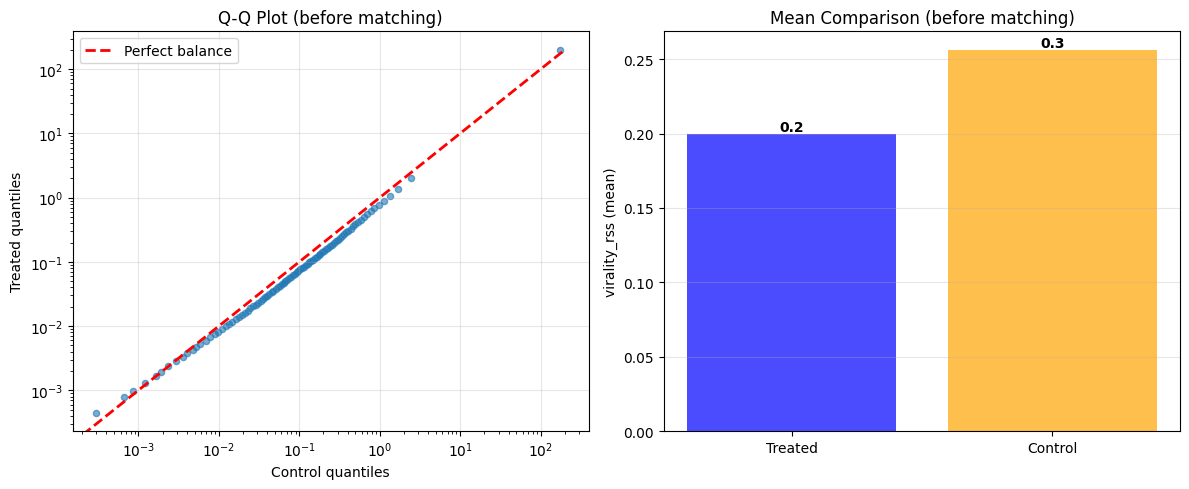


virality_rss (before matching):
  Treated: mean=0.2, median=0.0, n=280,703
  Control: mean=0.3, median=0.1, n=176,114
  Mean difference: -0.1


In [6]:
# Visualize balance (before matching)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Q-Q plot
ax1 = axes[0]
from scipy import stats
percentiles = np.linspace(0, 100, 100)
treated_q = np.percentile(treated[outcome_var], percentiles)
control_q = np.percentile(control[outcome_var], percentiles)
ax1.scatter(control_q, treated_q, alpha=0.6, s=20)
max_val = max(treated_q.max(), control_q.max())
ax1.plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Perfect balance')
ax1.set_xlabel(f'{outcome_var} (Control)')
ax1.set_ylabel(f'{outcome_var} (Treated)')
ax1.set_title('Q-Q Plot (before matching)')
ax1.legend()
ax1.grid(True, alpha=0.3)
if max_val > 100:
    ax1.set_xscale('log')
    ax1.set_yscale('log')

# Mean comparison bar plot
ax2 = axes[1]
means = [treated[outcome_var].mean(), control[outcome_var].mean()]
bars = ax2.bar(['Treated', 'Control'], means, color=['blue', 'orange'], alpha=0.7)
ax2.set_ylabel(f'{outcome_var} (mean)')
ax2.set_title('Mean Comparison (before matching)')
ax2.grid(True, alpha=0.3, axis='y')
# Add value labels on bars
for i, (bar, mean) in enumerate(zip(bars, means)):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'{mean:.1f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Print stats
print(f"\n{outcome_var} (before matching):")
print(f"  Treated: mean={treated[outcome_var].mean():.1f}, median={treated[outcome_var].median():.1f}, n={len(treated):,}")
print(f"  Control: mean={control[outcome_var].mean():.1f}, median={control[outcome_var].median():.1f}, n={len(control):,}")
print(f"  Mean difference: {treated[outcome_var].mean() - control[outcome_var].mean():.1f}")

## Step 2: Check Covariate Balance

Examine feature distributions between groups (like comparing age, education, etc. in LaLonde).


In [7]:
## Step 2: Convert columns to numeric and prepare covariates

# This cell modifies df_analysis in place - run this BEFORE Step 3

# 1. Convert all text/LIWC/style features that are stored as strings to numeric
print("Converting text/LIWC/style features to numeric...")
numeric_feature_cols = [
    'Num_characters', 'Num_characters_no_space', 'Frac_alpha', 'Frac_digits', 
    'Frac_uppercase', 'Frac_whitespace', 'Frac_special', 'Num_words', 
    'Num_unique_words', 'Num_long_words', 'Avg_word_length', 'Num_unique_stopwords',
    'Frac_stopwords', 'Num_sentences', 'Num_long_sentences', 'Avg_chars_per_sentence',
    'Avg_words_per_sentence', 'Automated_readability_index',
    'LIWC_Funct', 'LIWC_Pronoun', 'LIWC_Ppron', 'LIWC_I', 'LIWC_We', 'LIWC_You',
    'LIWC_SheHe', 'LIWC_They', 'LIWC_Ipron', 'LIWC_Article', 'LIWC_Verbs', 'LIWC_AuxVb',
    'LIWC_Past', 'LIWC_Present', 'LIWC_Future', 'LIWC_Adverbs', 'LIWC_Prep', 'LIWC_Conj',
    'LIWC_Negate', 'LIWC_Quant', 'LIWC_Numbers', 'LIWC_Swear', 'LIWC_Social', 'LIWC_Family',
    'LIWC_Friends', 'LIWC_Humans', 'LIWC_Affect', 'LIWC_Posemo', 'LIWC_Negemo', 'LIWC_Anx',
    'LIWC_Anger', 'LIWC_Sad', 'LIWC_CogMech', 'LIWC_Insight', 'LIWC_Cause', 'LIWC_Discrep',
    'LIWC_Tentat', 'LIWC_Certain', 'LIWC_Inhib', 'LIWC_Incl', 'LIWC_Excl', 'LIWC_Percept',
    'LIWC_See', 'LIWC_Hear', 'LIWC_Feel', 'LIWC_Bio', 'LIWC_Body', 'LIWC_Health', 'LIWC_Sexual',
    'LIWC_Ingest', 'LIWC_Relativ', 'LIWC_Motion', 'LIWC_Space', 'LIWC_Time', 'LIWC_Work',
    'LIWC_Achiev', 'LIWC_Leisure', 'LIWC_Home', 'LIWC_Money', 'LIWC_Relig', 'LIWC_Death',
    'LIWC_Assent', 'LIWC_Dissent', 'LIWC_Nonflu', 'LIWC_Filler',
    'subreddit_subscribers', 'created_utc'
]

for col in numeric_feature_cols:
    if col in df_analysis.columns:
        df_analysis[col] = pd.to_numeric(df_analysis[col], errors='coerce')

print(f"✓ Converted {len([c for c in numeric_feature_cols if c in df_analysis.columns])} columns to numeric")

# 2. Convert boolean/binary categorical columns to 0/1
print("\nConverting boolean columns to 0/1...")
boolean_cols = ['spoiler', 'over_18', 'is_video', 'is_self']
for col in boolean_cols:
    if col in df_analysis.columns:
        df_analysis[col] = df_analysis[col].map({True: 1, False: 0, 'True': 1, 'False': 0, 
                                                   'true': 1, 'false': 0, 1: 1, 0: 0})
        df_analysis[col] = pd.to_numeric(df_analysis[col], errors='coerce')

print(f"✓ Converted {len([c for c in boolean_cols if c in df_analysis.columns])} boolean columns to 0/1")

print("\n" + "="*80)
print("Numeric conversion complete. df_analysis is ready for propensity score matching.")
print("="*80)


Converting text/LIWC/style features to numeric...
✓ Converted 85 columns to numeric

Converting boolean columns to 0/1...
✓ Converted 4 boolean columns to 0/1

Numeric conversion complete. df_analysis is ready for propensity score matching.


In [8]:
# Diagnostic: check dtypes and sample values
print("Column dtypes and sample values:\n")
for col in df_analysis.columns:  # first 50 columns
    sample_val = df_analysis[col].dropna().iloc[0] if df_analysis[col].notna().any() else None
    print(f"{col:40s} {str(df_analysis[col].dtype):15s} sample: {sample_val}")

Column dtypes and sample values:

SOURCE_SUBREDDIT                         object          sample: leagueoflegends
TARGET_SUBREDDIT                         object          sample: teamredditteams
POST_ID                                  object          sample: 1u4nrps
TIMESTAMP                                datetime64[ns]  sample: 2013-12-31 16:39:58
LINK_SENTIMENT                           int64           sample: 1
source_type                              object          sample: body
Num_characters                           float64         sample: 345.0
Num_characters_no_space                  float64         sample: 298.0
Frac_alpha                               float64         sample: 0.75652173913
Frac_digits                              float64         sample: 0.0173913043478
Frac_uppercase                           float64         sample: 0.0869565217391
Frac_whitespace                          float64         sample: 0.150724637681
Frac_special                             float

## Step 3: Estimate Propensity Scores

Use logistic regression to estimate P(treatment | covariates).


In [59]:
any([x=='downs' for x in df_analysis.columns.tolist()])

True

In [62]:
# Build covariate list from numeric columns (must run AFTER cell 11)
print("Building covariate list...")
numeric_cols = df_analysis.select_dtypes(include=[np.number]).columns.tolist()

exclude = [
    # Treatment and outcome
    'treat', 'ups', 'virality_rss', 'score', 'num_comments', 'total_votes', 'downs', 'subreddit_subscribers',
    # Sentiment (defines treatment)
    'Sentiment_compound_vader', 'Sentiment_pos_vader', 'Sentiment_neg_vader',
    # Post-treatment engagement
    'total_awards_received', 'upvote_ratio', 'gilded', 'downs', 'num_crossposts',
    # Constant
    'is_video',
    # Columns with all missing values (moderation/metadata)
    'created', 'approved_by', 'mod_reason_title', 'top_awarded_type', 
    'report_reasons', 'removed_by', 'num_reports', 'mod_reason_by', 
    'treatment_tags', 'view_count', 'banned_at_utc', 'likes', 
    'banned_by', 'num_duplicates', 'discussion_type', 'mod_note', 
    'category', 'approved_at_utc', 'pwls', 'wls',
    'Frac_special', 'LIWC_Pronoun', # this row is the linearly dependent columns which cause issues with regression
    'is_self', 'created_utc' # unneccesary columns from Reddit API
]

covariates = [c for c in numeric_cols if c not in exclude]
print(f"✓ Selected {len(covariates)} covariates (excluded {len(exclude)} columns)")

# Drop rows with missing values on covariates, treatment, or outcome
print("\nDropping rows with missing values...")
df_clean = df_analysis.dropna(subset=covariates + ['treat', outcome_var]).copy()
print(f"  Original: {df_analysis.shape[0]} rows")
print(f"  After dropna: {df_clean.shape[0]} rows")
print(f"  Dropped: {df_analysis.shape[0] - df_clean.shape[0]} rows")

if df_clean.shape[0] == 0:
    raise ValueError("ERROR: All rows dropped! Check that cell 11 was run first.")

# Standardize continuous features (like LaLonde example)
print("\nStandardizing covariates...")
for col in covariates:
    df_clean[col] = (df_clean[col] - df_clean[col].mean()) / df_clean[col].std()

print("✓ Standardization complete")


Building covariate list...
✓ Selected 84 covariates (excluded 41 columns)

Dropping rows with missing values...
  Original: 456817 rows
  After dropna: 456817 rows
  Dropped: 0 rows

Standardizing covariates...
✓ Standardization complete


In [63]:
# Identify variables most associated with virality
print("="*80)
print("ANALYZING VARIABLES MOST ASSOCIATED WITH VIRALITY")
print("="*80)

from sklearn.ensemble import RandomForestRegressor
from scipy.stats import spearmanr
import warnings
warnings.filterwarnings('ignore')

# Prepare data (use non-standardized for correlation, but standardized for RF)
df_virality = df_clean.copy()
# Un-standardize for correlation analysis (more interpretable)
for col in covariates:
    if col in df_virality.columns:
        # We'll use original values for correlation
        pass

# Method 1: Pearson correlation
print("\n1. PEARSON CORRELATION WITH VIRALITY:")
print("-" * 80)
correlations = {}
for col in covariates:
    if col in df_virality.columns:
        corr = df_virality[col].corr(df_virality[outcome_var])
        if not np.isnan(corr):
            correlations[col] = corr

corr_sorted = sorted(correlations.items(), key=lambda x: abs(x[1]), reverse=True)
print(f"\nTop 20 variables by absolute correlation:")
for i, (var, corr) in enumerate(corr_sorted[:20], 1):
    print(f"  {i:2d}. {var:30s}: {corr:7.4f}")

# Method 2: Spearman correlation (handles non-linear relationships better)
print("\n2. SPEARMAN CORRELATION WITH VIRALITY:")
print("-" * 80)
spearman_corrs = {}
for col in covariates:
    if col in df_virality.columns:
        try:
            corr, pval = spearmanr(df_virality[col], df_virality[outcome_var])
            if not np.isnan(corr):
                spearman_corrs[col] = (corr, pval)
        except:
            pass

spearman_sorted = sorted(spearman_corrs.items(), key=lambda x: abs(x[1][0]), reverse=True)
print(f"\nTop 20 variables by absolute Spearman correlation:")
for i, (var, (corr, pval)) in enumerate(spearman_sorted[:20], 1):
    sig = "***" if pval < 0.001 else "**" if pval < 0.01 else "*" if pval < 0.05 else ""
    print(f"  {i:2d}. {var:30s}: {corr:7.4f} (p={pval:.4f}) {sig}")

# Method 3: Random Forest Feature Importance
print("\n3. RANDOM FOREST FEATURE IMPORTANCE:")
print("-" * 80)
print("Training Random Forest model...")

# Sample data if too large (for speed)
sample_size = min(100000, len(df_virality))
if sample_size < len(df_virality):
    df_sample = df_virality.sample(n=sample_size, random_state=42)
    print(f"  Using sample of {sample_size:,} rows for speed")
else:
    df_sample = df_virality

X = df_sample[covariates].fillna(0)  # Fill any remaining NaNs
y = df_sample[outcome_var]

# Train Random Forest
rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X, y)

# Get feature importance
feature_importance = pd.DataFrame({
    'variable': covariates,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\nTop 20 variables by Random Forest importance:")
for i, (idx, row) in enumerate(feature_importance.head(20).iterrows(), 1):
    print(f"  {i:2d}. {row['variable']:30s}: {row['importance']:.6f}")

# Method 4: Combined ranking
print("\n4. COMBINED RANKING (average rank across all methods):")
print("-" * 80)

# Create ranking dictionaries
pearson_ranks = {var: rank for rank, (var, _) in enumerate(corr_sorted, 1)}
spearman_ranks = {var: rank for rank, (var, _) in enumerate(spearman_sorted, 1)}
rf_ranks = {row['variable']: rank for rank, (_, row) in enumerate(feature_importance.iterrows(), 1)}

# Get all variables that appear in at least one ranking
all_vars = set(pearson_ranks.keys()) | set(spearman_ranks.keys()) | set(rf_ranks.keys())

# Calculate average rank
combined_ranks = {}
for var in all_vars:
    ranks = []
    if var in pearson_ranks:
        ranks.append(pearson_ranks[var])
    if var in spearman_ranks:
        ranks.append(spearman_ranks[var])
    if var in rf_ranks:
        ranks.append(rf_ranks[var])
    if ranks:
        combined_ranks[var] = np.mean(ranks)

combined_sorted = sorted(combined_ranks.items(), key=lambda x: x[1])

print(f"\nTop 20 variables by combined ranking (lower = better):")
for i, (var, avg_rank) in enumerate(combined_sorted[:20], 1):
    pearson_r = pearson_ranks.get(var, '-')
    spearman_r = spearman_ranks.get(var, '-')
    rf_r = rf_ranks.get(var, '-')
    print(f"  {i:2d}. {var:30s}: avg_rank={avg_rank:.1f} (Pearson={pearson_r}, Spearman={spearman_r}, RF={rf_r})")

print("\n" + "="*80)
print("SUMMARY: Most important variables for virality prediction")
print("="*80)
print("\nTop 10 variables (by combined ranking):")
for i, (var, _) in enumerate(combined_sorted[:10], 1):
    print(f"  {i}. {var}")

# Store top variables for reference
top_virality_vars = [var for var, _ in combined_sorted[:20]]
print(f"\n✓ Identified {len(top_virality_vars)} top variables associated with virality")


ANALYZING VARIABLES MOST ASSOCIATED WITH VIRALITY

1. PEARSON CORRELATION WITH VIRALITY:
--------------------------------------------------------------------------------

Top 20 variables by absolute correlation:
   1. Num_characters_no_space       :  0.0676
   2. Num_long_words                :  0.0667
   3. Num_unique_words              :  0.0666
   4. Num_characters                :  0.0666
   5. Num_words                     :  0.0643
   6. Num_unique_stopwords          :  0.0636
   7. Num_sentences                 :  0.0569
   8. Num_long_sentences            :  0.0562
   9. LIWC_I                        : -0.0255
  10. LIWC_SheHe                    :  0.0249
  11. Automated_readability_index   :  0.0242
  12. Avg_chars_per_sentence        :  0.0240
  13. LINK_SENTIMENT                : -0.0238
  14. LIWC_Social                   :  0.0225
  15. Avg_words_per_sentence        :  0.0209
  16. LIWC_They                     :  0.0192
  17. LIWC_Tentat                   : -0.0190
  18.

In [64]:
# Diagnostic: check missing values per covariate
print("Missing value counts per covariate:")
missing_counts = df_analysis[covariates].isna().sum().sort_values(ascending=False)
print(missing_counts.head(20))

print(f"\nTotal rows in df_analysis: {len(df_analysis)}")
print(f"Rows with NO missing values across ALL {len(covariates)} covariates + treat + outcome:")

# Check how many rows survive if we drop NAs
test_clean = df_analysis.dropna(subset=covariates + ['treat', outcome_var])
print(f"  {len(test_clean)} rows")

if len(test_clean) == 0:
    print("\n⚠️ WARNING: No rows survive after dropping NAs!")
    print("You need to either:")
    print("  1. Reduce the number of covariates (drop columns with many NAs)")
    print("  2. Impute missing values")
    print("  3. Use a subset of covariates")

Missing value counts per covariate:
LINK_SENTIMENT                 0
Num_characters                 0
Num_characters_no_space        0
Frac_alpha                     0
Frac_digits                    0
Frac_uppercase                 0
Frac_whitespace                0
Num_words                      0
Num_unique_words               0
Num_long_words                 0
Avg_word_length                0
Num_unique_stopwords           0
Frac_stopwords                 0
Num_sentences                  0
Num_long_sentences             0
Avg_chars_per_sentence         0
Avg_words_per_sentence         0
Automated_readability_index    0
LIWC_Funct                     0
LIWC_Ppron                     0
dtype: int64

Total rows in df_analysis: 456817
Rows with NO missing values across ALL 84 covariates + treat + outcome:
  456817 rows


In [65]:
# Check for NaN or constant columns after standardization
print("\nChecking standardized covariates...")
for col in covariates:
    if df_clean[col].isna().all():
        print(f"  ⚠️ {col}: ALL NaN after standardization")
    elif df_clean[col].std() == 0 or df_clean[col].isna().any():
        print(f"  ⚠️ {col}: has NaN or is constant")

print(f"\nShape of df_clean after standardization: {df_clean.shape}")
print(f"Any NaN in covariates: {df_clean[covariates].isna().any().any()}")


Checking standardized covariates...

Shape of df_clean after standardization: (456817, 198)
Any NaN in covariates: False


In [66]:
# Fit logistic regression on ENTIRE cleaned dataset (same approach as LaLonde)
# No train/test split - goal is to balance, not predict (see Rosenbaum p. 74)
print("Fitting logistic regression for propensity scores...")
print(f"Number of covariates: {len(covariates)}")

formula = 'treat ~ ' + ' + '.join(covariates)
mod = smf.logit(formula=formula, data=df_clean)
res = mod.fit(maxiter=100, method='lbfgs')  # Increased iterations, better optimizer

# Check convergence
if not res.mle_retvals['converged']:
    print("WARNING: Model did not converge. Results may be unreliable.")
else:
    print("Model converged successfully")

# Extract propensity scores
df_clean['Propensity_score'] = res.predict()

print("\n" + "="*80)
print(res.summary())
print("="*80)
print(f"\nPropensity score range: [{df_clean['Propensity_score'].min():.4f}, {df_clean['Propensity_score'].max():.4f}]")


Fitting logistic regression for propensity scores...
Number of covariates: 84

                           Logit Regression Results                           
Dep. Variable:                  treat   No. Observations:               456817
Model:                          Logit   Df Residuals:                   456732
Method:                           MLE   Df Model:                           84
Date:                Sat, 13 Dec 2025   Pseudo R-squ.:                  0.3776
Time:                        14:37:34   Log-Likelihood:            -1.8955e+05
converged:                      False   LL-Null:                   -3.0456e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                       0.6407      0.005    140.966      0.000       0.632       0.650
L

In [67]:
def get_similarity(propensity_score1, propensity_score2):
    '''Calculate similarity for instances with given propensity scores'''
    return 1 - np.abs(propensity_score1 - propensity_score2)


In [68]:
# FAST Propensity Score Matching (replaces slow nested loop approach)
import time
from scipy.spatial.distance import cdist
from sklearn.neighbors import NearestNeighbors

print("Starting matching...")
start_time = time.time()

# Separate groups
treatment_df = df_clean[df_clean['treat'] == 1].copy()
control_df = df_clean[df_clean['treat'] == 0].copy()

n_treatment = len(treatment_df)
n_control = len(control_df)
print(f"Treatment: {n_treatment:,} | Control: {n_control:,} | Total pairs to check: {n_treatment * n_control:,}")

# Estimate time (rough)
if n_treatment * n_control > 1_000_000:
    print(f"⚠ WARNING: This will create {n_treatment * n_control:,} edges - very slow!")
    print("   Using FAST nearest-neighbor matching instead...")
    
    # FAST: Nearest neighbor matching with caliper
    caliper = 0.00001  # Only match within 0.1 propensity score difference
    
    treatment_ps = treatment_df['Propensity_score'].values.reshape(-1, 1)
    control_ps = control_df['Propensity_score'].values.reshape(-1, 1)
    
    # Find nearest neighbors
    nn = NearestNeighbors(n_neighbors=1, metric='manhattan')
    nn.fit(control_ps)
    distances, indices = nn.kneighbors(treatment_ps)
    
    # Apply caliper
    valid = distances.flatten() <= caliper
    matched_treatment = treatment_df.index[valid]
    matched_control = control_df.index[indices[valid].flatten()]
    
    matching = list(zip(matched_treatment, matched_control))
    print(f"✓ Matched {len(matching):,} pairs (within caliper={caliper}) in {time.time() - start_time:.1f}s")
    
else:
    # Original approach for small datasets
    print("Using full graph matching (small dataset)...")
    G = nx.Graph()
    
    for i, (control_id, control_row) in enumerate(control_df.iterrows()):
        if (i + 1) % 100 == 0:
            print(f"  Processing control {i+1}/{n_control}...")
        for treatment_id, treatment_row in treatment_df.iterrows():
            similarity = 1 - abs(control_row['Propensity_score'] - treatment_row['Propensity_score'])
            G.add_weighted_edges_from([(control_id, treatment_id, similarity)])
    
    matching = nx.max_weight_matching(G)
    print(f"✓ Matched {len(matching):,} pairs in {time.time() - start_time:.1f}s")

Starting matching...
Treatment: 280,703 | Control: 176,114 | Total pairs to check: 49,435,728,142
⚠ WARNING: This will create 49,435,728,142 edges - very slow!
   Using FAST nearest-neighbor matching instead...
✓ Matched 210,804 pairs (within caliper=1e-05) in 2.4s


In [69]:
# Extract matched dataset
matched = [i[0] for i in list(matching)] + [i[1] for i in list(matching)]
balanced_df = df_clean.loc[matched]  # Changed from iloc to loc
print(f"Balanced dataset size: {len(balanced_df)}")

Balanced dataset size: 421608


In [70]:
# ============================================================================
# COVARIATE BALANCE TABLE: Before vs After Matching
# ============================================================================
# This table helps evaluate matching quality and find optimal caliper value

print("=" * 100)
print("COVARIATE BALANCE TABLE")
print("=" * 100)

# Separate groups before matching
treated_before = df_clean[df_clean['treat'] == 1]
control_before = df_clean[df_clean['treat'] == 0]

# Separate groups after matching
treated_matched = balanced_df[balanced_df['treat'] == 1]
control_matched = balanced_df[balanced_df['treat'] == 0]

# Function to calculate standardized mean difference (SMD)
def smd(mean_treated, mean_control, std_treated, std_control):
    """Calculate standardized mean difference using pooled SD"""
    pooled_std = np.sqrt((std_treated**2 + std_control**2) / 2)
    if pooled_std == 0:
        return np.nan
    return (mean_treated - mean_control) / pooled_std

# Calculate matched propensity score distances
matched_distances = []
for treatment_id, control_id in matching:
    ps_treat = df_clean.loc[treatment_id, 'Propensity_score']
    ps_control = df_clean.loc[control_id, 'Propensity_score']
    matched_distances.append(abs(ps_treat - ps_control))

# Build balance table
balance_data = []

# Add sample sizes
balance_data.append({
    'Covariate': 'Sample Size',
    'Treated_Before': len(treated_before),
    'Control_Before': len(control_before),
    'Treated_After': len(treated_matched),
    'Control_After': len(control_matched),
    'SMD_Before': np.nan,
    'SMD_After': np.nan
})

# Add propensity score SMD
ps_treated_before_mean = treated_before['Propensity_score'].mean()
ps_control_before_mean = control_before['Propensity_score'].mean()
ps_treated_before_std = treated_before['Propensity_score'].std()
ps_control_before_std = control_before['Propensity_score'].std()
ps_smd_before = smd(ps_treated_before_mean, ps_control_before_mean, 
                    ps_treated_before_std, ps_control_before_std)

ps_treated_after_mean = treated_matched['Propensity_score'].mean()
ps_control_after_mean = control_matched['Propensity_score'].mean()
ps_treated_after_std = treated_matched['Propensity_score'].std()
ps_control_after_std = control_matched['Propensity_score'].std()
ps_smd_after = smd(ps_treated_after_mean, ps_control_after_mean,
                   ps_treated_after_std, ps_control_after_std)

balance_data.append({
    'Covariate': 'Propensity Score',
    'Treated_Before': f"{ps_treated_before_mean:.4f}",
    'Control_Before': f"{ps_control_before_mean:.4f}",
    'Treated_After': f"{ps_treated_after_mean:.4f}",
    'Control_After': f"{ps_control_after_mean:.4f}",
    'SMD_Before': ps_smd_before,
    'SMD_After': ps_smd_after
})

# Add separator
balance_data.append({
    'Covariate': '-' * 80,
    'Treated_Before': '',
    'Control_Before': '',
    'Treated_After': '',
    'Control_After': '',
    'SMD_Before': np.nan,
    'SMD_After': np.nan
})

# Calculate balance for each covariate
for cov in covariates:
    if cov not in df_clean.columns:
        continue
    
    # Before matching
    mean_t_before = treated_before[cov].mean()
    mean_c_before = control_before[cov].mean()
    std_t_before = treated_before[cov].std()
    std_c_before = control_before[cov].std()
    smd_before = smd(mean_t_before, mean_c_before, std_t_before, std_c_before)
    
    # After matching
    mean_t_after = treated_matched[cov].mean()
    mean_c_after = control_matched[cov].mean()
    std_t_after = treated_matched[cov].std()
    std_c_after = control_matched[cov].std()
    smd_after = smd(mean_t_after, mean_c_after, std_t_after, std_c_after)
    
    balance_data.append({
        'Covariate': cov,
        'Treated_Before': f"{mean_t_before:.4f}",
        'Control_Before': f"{mean_c_before:.4f}",
        'Treated_After': f"{mean_t_after:.4f}",
        'Control_After': f"{mean_c_after:.4f}",
        'SMD_Before': smd_before,
        'SMD_After': smd_after
    })

# Create DataFrame
balance_df = pd.DataFrame(balance_data)

# Format SMD columns
balance_df['SMD_Before'] = balance_df['SMD_Before'].apply(
    lambda x: f"{x:.4f}" if not np.isnan(x) else ""
)
balance_df['SMD_After'] = balance_df['SMD_After'].apply(
    lambda x: f"{x:.4f}" if not np.isnan(x) else ""
)

# Print table with highlighting
print("\n" + "=" * 100)
print(f"{'Covariate':<40} {'Treated_Before':<15} {'Control_Before':<15} {'Treated_After':<15} {'Control_After':<15} {'SMD_Before':<12} {'SMD_After':<12}")
print("=" * 100)

for _, row in balance_df.iterrows():
    if row['Covariate'].startswith('-'):
        print("-" * 100)
    else:
        # Check if SMD_After is unacceptable
        smd_after_str = row['SMD_After']
        is_unacceptable = False
        warning = ""
        
        if smd_after_str != '':
            try:
                smd_val = float(smd_after_str)
                if not np.isnan(smd_val):
                    abs_smd = abs(smd_val)
                    if abs_smd >= 0.25:
                        is_unacceptable = True
                        warning = " ⚠⚠⚠ POOR"
                    elif abs_smd >= 0.1:
                        is_unacceptable = True
                        warning = " ⚠⚠ ACCEPTABLE"
            except:
                pass
        
        # Format the row
        cov_name = row['Covariate']
        if is_unacceptable:
            cov_name = f"⚠ {cov_name}"
        
        print(f"{cov_name:<40} {row['Treated_Before']:<15} {row['Control_Before']:<15} "
              f"{row['Treated_After']:<15} {row['Control_After']:<15} {row['SMD_Before']:<12} {smd_after_str:<12}{warning}")

print("=" * 100)

# Summary statistics
print("\n" + "=" * 100)
print("MATCHING QUALITY SUMMARY")
print("=" * 100)
print(f"\nSample Sizes:")
print(f"  Before: Treated={len(treated_before):,}, Control={len(control_before):,}")
print(f"  After:  Treated={len(treated_matched):,}, Control={len(control_matched):,}")
print(f"  Match rate: {len(treated_matched)/len(treated_before)*100:.1f}% of treated units matched")

print(f"\nPropensity Score Balance:")
print(f"  SMD Before: {ps_smd_before:.4f}")
print(f"  SMD After:  {ps_smd_after:.4f}")
print(f"  Improvement: {abs(ps_smd_before) - abs(ps_smd_after):.4f}")

print(f"\nMatched Propensity Score Distances:")
print(f"  Min:  {min(matched_distances):.6f}")
print(f"  Mean: {np.mean(matched_distances):.6f}")
print(f"  Max:  {max(matched_distances):.6f}")
print(f"  Median: {np.median(matched_distances):.6f}")
print(f"  P95:   {np.percentile(matched_distances, 95):.6f}")

# Count covariates with |SMD| > 0.1 (threshold for imbalance)
smd_after_values = []
for _, row in balance_df.iterrows():
    if row['Covariate'] not in ['Sample Size', '-' * 80] and row['SMD_After'] != '':
        try:
            smd_val = float(row['SMD_After'])
            if not np.isnan(smd_val):
                smd_after_values.append(abs(smd_val))
        except:
            pass

imbalanced_count = sum(1 for x in smd_after_values if x > 0.1)
poor_count = sum(1 for x in smd_after_values if x >= 0.25)
acceptable_count = sum(1 for x in smd_after_values if 0.1 <= x < 0.25)

print(f"\nCovariate Balance After Matching:")
print(f"  Covariates with |SMD| > 0.1: {imbalanced_count}/{len(smd_after_values)} ({imbalanced_count/len(smd_after_values)*100:.1f}%)")
print(f"    - Poor (|SMD| ≥ 0.25): {poor_count}")
print(f"    - Acceptable (0.1 ≤ |SMD| < 0.25): {acceptable_count}")
print(f"  Mean |SMD|: {np.mean(smd_after_values):.4f}")
print(f"  Max |SMD|:  {max(smd_after_values):.4f}")

# List problematic covariates explicitly
print(f"\n⚠ PROBLEMATIC COVARIATES (|SMD| ≥ 0.1 after matching):")
problematic_covs = []
for _, row in balance_df.iterrows():
    if row['Covariate'] not in ['Sample Size', 'Propensity Score', '-' * 80] and row['SMD_After'] != '':
        try:
            smd_val = float(row['SMD_After'])
            if not np.isnan(smd_val) and abs(smd_val) >= 0.1:
                status = "POOR" if abs(smd_val) >= 0.25 else "ACCEPTABLE"
                problematic_covs.append((row['Covariate'], smd_val, status))
        except:
            pass

if problematic_covs:
    # Sort by absolute SMD (worst first)
    problematic_covs.sort(key=lambda x: abs(x[1]), reverse=True)
    for cov, smd_val, status in problematic_covs:
        print(f"  {status:12s} | {cov:40s} | SMD = {smd_val:+.4f}")
else:
    print("  ✓ None! All covariates are well balanced (|SMD| < 0.1)")

print("\n" + "=" * 100)
print("INTERPRETATION:")
print("=" * 100)
print("  • SMD < 0.1: Good balance (small difference)")
print("  • 0.1 ≤ SMD < 0.25: Acceptable balance")
print("  • SMD ≥ 0.25: Poor balance (large difference)")
print("  • If many covariates have |SMD| > 0.1 after matching, consider:")
print("    - Reducing caliper (e.g., 0.05 instead of 0.1)")
print("    - Using different matching algorithm (e.g., optimal matching)")
print("    - Adding exact matching constraints")
print("=" * 100)


COVARIATE BALANCE TABLE

Covariate                                Treated_Before  Control_Before  Treated_After   Control_After   SMD_Before   SMD_After   
Sample Size                              280703          176114          210804          210804                                   
Propensity Score                         0.7873          0.3390          0.7564          0.7564          1.8507       0.0000      
----------------------------------------------------------------------------------------------------
LINK_SENTIMENT                           0.2479          -0.3952         0.2175          0.1879          0.6277       0.0410      
⚠ Num_characters                         0.0404          -0.0645         0.0534          -0.1344         0.1055       0.2081       ⚠⚠ ACCEPTABLE
⚠ Num_characters_no_space                0.0386          -0.0615         0.0530          -0.1367         0.1006       0.2114       ⚠⚠ ACCEPTABLE
Frac_alpha                               -0.0967         0.1

## Step 5:  Add Exact Match Constraints



In [71]:
# Example: Match only within same source_type
# Uncomment to use:

# G_constrained = nx.Graph()
# for control_id, control_row in control_df.iterrows():
#     for treatment_id, treatment_row in treatment_df.iterrows():
#         # Add edge only if same source_type (like matching on race)
#         if control_row.get('source_type') == treatment_row.get('source_type'):
#             similarity = get_similarity(control_row['Propensity_score'],
#                                        treatment_row['Propensity_score'])
#             G_constrained.add_weighted_edges_from([(control_id, treatment_id, similarity)])
# 
# matching = nx.max_weight_matching(G_constrained)
# matched = [i[0] for i in list(matching)] + [i[1] for i in list(matching)]
# balanced_df = df_clean.iloc[matched]


## Step 6: Final Analysis on Matched Data

Compare outcomes after matching (like comparing re78 after matching in LaLonde).


In [72]:
treated_matched = balanced_df[balanced_df['treat'] == 1]
control_matched = balanced_df[balanced_df['treat'] == 0]

print("Treated (matched):"); print(treated_matched[outcome_var].describe())
print("\nControl (matched):"); print(control_matched[outcome_var].describe())


Treated (matched):
count    210804.000000
mean          0.205120
std           0.993237
min           0.000000
25%           0.008201
50%           0.047022
75%           0.173038
max         202.646563
Name: virality_rss, dtype: float64

Control (matched):
count    210804.000000
mean          0.211560
std           0.660649
min           0.000000
25%           0.008415
50%           0.055384
75%           0.206096
max          67.110505
Name: virality_rss, dtype: float64


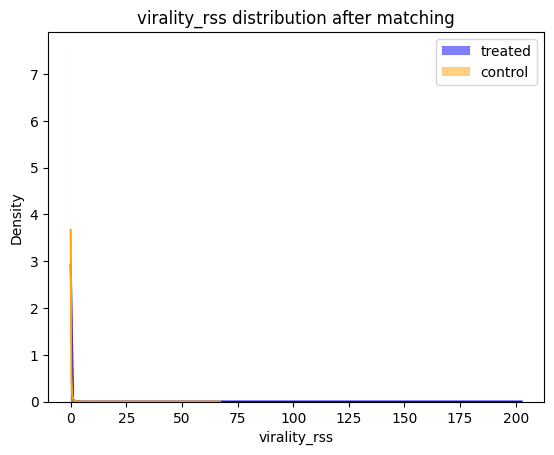


*** Average Treatment Effect: -0.0064 ***


In [73]:
# Final visualization (same style as LaLonde)
ax = sns.histplot(treated_matched[outcome_var], kde=True, stat='density', 
                  color='blue', label='treated')
ax = sns.histplot(control_matched[outcome_var], kde=True, stat='density', 
                  color='orange', label='control')
ax.set(title=f'{outcome_var} distribution after matching',
       xlabel=outcome_var, ylabel='Density')
plt.legend()
plt.show()

# Calculate treatment effect
att = treated_matched[outcome_var].mean() - control_matched[outcome_var].mean()
print(f"\n*** Average Treatment Effect: {att:.4f} ***")



Top 1% threshold (99th percentile): 2.04
Max values in top 1%: Treated=202.65, Control=67.11


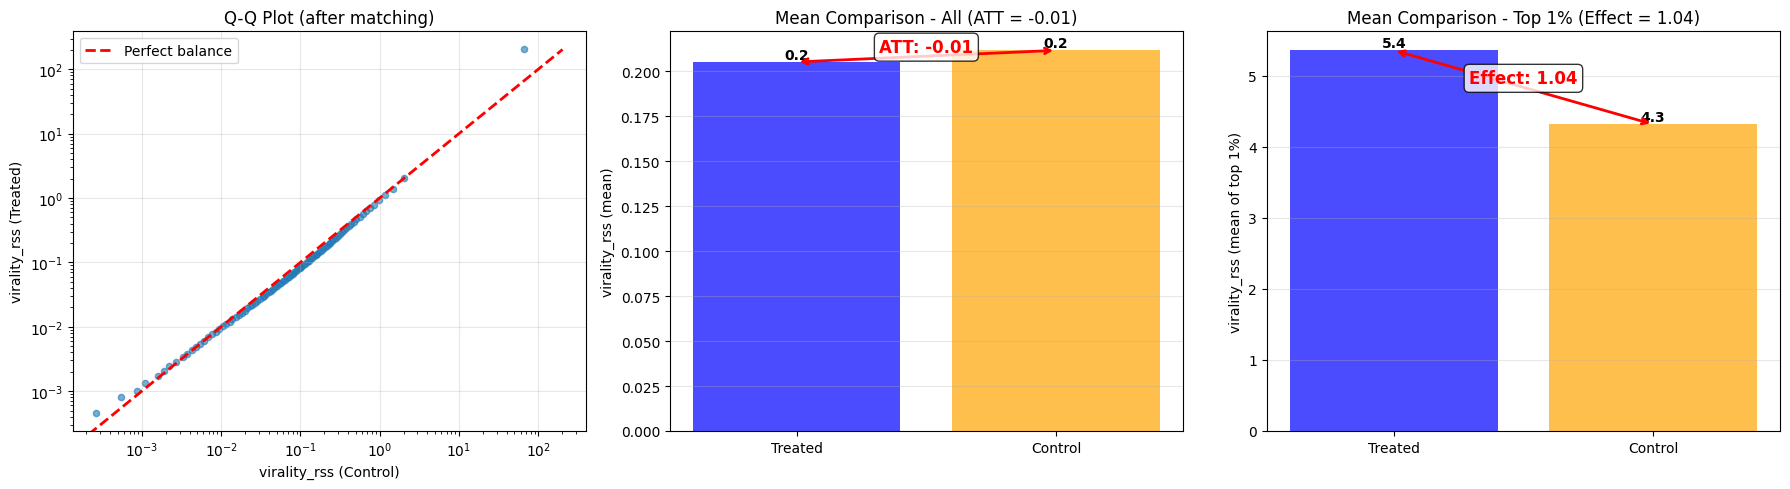


virality_rss (after matching):
  Treated: mean=0.21, median=0.05, n=210,804
  Control: mean=0.21, median=0.06, n=210,804

*** Average Treatment Effect (ATT): -0.0064 ***
   Interpretation: Positive sentiment posts get -0.01 more upvotes on average

*** Mean Comparison - Top 1% of posts: 1.0403 ***
   Threshold (99th percentile): 2.04
   Max values: Treated=202.65, Control=67.11
   Mean values: Treated=5.36, Control=4.32
   Sample sizes: Treated=2,091, Control=2,126
   Interpretation: Among the top 1% most viral posts, positive sentiment posts have mean virality 1.04 different from control


In [74]:
# Visualize results after matching
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Q-Q plot (after matching)
ax1 = axes[0]
from scipy import stats
percentiles = np.linspace(0, 100, 100)
treated_matched_q = np.percentile(treated_matched[outcome_var], percentiles)
control_matched_q = np.percentile(control_matched[outcome_var], percentiles)
ax1.scatter(control_matched_q, treated_matched_q, alpha=0.6, s=20)
max_val = max(treated_matched_q.max(), control_matched_q.max())
ax1.plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Perfect balance')
ax1.set_xlabel(f'{outcome_var} (Control)')
ax1.set_ylabel(f'{outcome_var} (Treated)')
ax1.set_title('Q-Q Plot (after matching)')
ax1.legend()
ax1.grid(True, alpha=0.3)
if max_val > 100:
    ax1.set_xscale('log')
    ax1.set_yscale('log')

# Mean comparison with ATT highlighted (all percentiles)
ax2 = axes[1]
means = [treated_matched[outcome_var].mean(), control_matched[outcome_var].mean()]
bars = ax2.bar(['Treated', 'Control'], means, color=['blue', 'orange'], alpha=0.7)
ax2.set_ylabel(f'{outcome_var} (mean)')
ax2.set_title(f'Mean Comparison - All (ATT = {att:.2f})')
ax2.grid(True, alpha=0.3, axis='y')

# Add value labels and ATT annotation
for i, (bar, mean) in enumerate(zip(bars, means)):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'{mean:.1f}', ha='center', va='bottom', fontweight='bold')

# Add ATT arrow
ax2.annotate('', xy=(0, means[0]), xytext=(1, means[1]),
            arrowprops=dict(arrowstyle='<->', color='red', lw=2))
ax2.text(0.5, (means[0] + means[1])/2, f'ATT: {att:.2f}',
        ha='center', va='bottom', fontsize=12, fontweight='bold', color='red',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Mean comparison for top 1% of posts (99th to 100th percentile)
ax3 = axes[2]
# Calculate 99th percentile threshold from matched dataset
threshold_99 = balanced_df[outcome_var].quantile(0.99)
# Filter to top 1% (posts from 99th to 100th percentile)
treated_top1 = treated_matched[treated_matched[outcome_var] >= threshold_99]
control_top1 = control_matched[control_matched[outcome_var] >= threshold_99]
# Calculate mean of top 1%
means_top1 = [treated_top1[outcome_var].mean(), control_top1[outcome_var].mean()]
att_top1 = means_top1[0] - means_top1[1]
# Print max values to verify correct posts are included
print(f"\nTop 1% threshold (99th percentile): {threshold_99:.2f}")
print(f"Max values in top 1%: Treated={treated_top1[outcome_var].max():.2f}, Control={control_top1[outcome_var].max():.2f}")
bars_top1 = ax3.bar(['Treated', 'Control'], means_top1, color=['blue', 'orange'], alpha=0.7)
ax3.set_ylabel(f'{outcome_var} (mean of top 1%)')
ax3.set_title(f'Mean Comparison - Top 1% (Effect = {att_top1:.2f})')
ax3.grid(True, alpha=0.3, axis='y')

# Add value labels and effect annotation
for i, (bar, mean) in enumerate(zip(bars_top1, means_top1)):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'{mean:.1f}', ha='center', va='bottom', fontweight='bold')

# Add effect arrow
ax3.annotate('', xy=(0, means_top1[0]), xytext=(1, means_top1[1]),
            arrowprops=dict(arrowstyle='<->', color='red', lw=2))
ax3.text(0.5, (means_top1[0] + means_top1[1])/2, f'Effect: {att_top1:.2f}',
        ha='center', va='bottom', fontsize=12, fontweight='bold', color='red',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

# Print comparison
print(f"\n{outcome_var} (after matching):")
print(f"  Treated: mean={treated_matched[outcome_var].mean():.2f}, median={treated_matched[outcome_var].median():.2f}, n={len(treated_matched):,}")
print(f"  Control: mean={control_matched[outcome_var].mean():.2f}, median={control_matched[outcome_var].median():.2f}, n={len(control_matched):,}")
print(f"\n*** Average Treatment Effect (ATT): {att:.4f} ***")
print(f"   Interpretation: Positive sentiment posts get {att:.2f} more upvotes on average")
print(f"\n*** Mean Comparison - Top 1% of posts: {att_top1:.4f} ***")
print(f"   Threshold (99th percentile): {threshold_99:.2f}")
print(f"   Max values: Treated={treated_top1[outcome_var].max():.2f}, Control={control_top1[outcome_var].max():.2f}")
print(f"   Mean values: Treated={means_top1[0]:.2f}, Control={means_top1[1]:.2f}")
print(f"   Sample sizes: Treated={len(treated_top1):,}, Control={len(control_top1):,}")
print(f"   Interpretation: Among the top 1% most viral posts, positive sentiment posts have mean virality {att_top1:.2f} different from control")